> **🧭 Navigasi Proyek CRISP-DM:**
> [🏠 00. Business Understanding](./00_Index_dan_Business_Understanding.ipynb) | [📊 01. Data Understanding & EDA](./01_Data_Understanding_dan_EDA.ipynb) | [⚙️ 02. Data Preparation & 32 Fitur](./02_Data_Preparation_Chunking_dan_Ekstraksi_32Fitur.ipynb) | [🧠 03. Modeling & Benchmarking](./03_Modeling_dan_Benchmarking.ipynb) | [🚀 04. Evaluation & Deployment](./04_Evaluation_dan_Simulasi_Deployment.ipynb)

# 📊 FASE 2 CRISP-DM: Data Understanding & Exploratory Data Analysis (EDA)
## Eksplorasi Karakteristik Fisik & Akustik Sinyal Audio

---

### 📋 Deskripsi Fase Data Understanding
Tujuan utama dari fase ini adalah:
1. Mengidentifikasi karakteristik teknis rekaman mentah (sample rate, durasi, format).
2. Mengeksplorasi sinyal audio dalam **domain waktu (*waveform*)** untuk melihat dinamika amplitudo.
3. Mengeksplorasi sinyal audio dalam **domain frekuensi (*mel-spectrogram*)** untuk melihat distribusi daya akustik.
4. Menemukan dasar fisis yang membedakan suara manusia di ruangan ramai vs deru stasioner AC/kipas di ruangan sepi.


In [1]:
import os
import sys
import glob
import warnings
import numpy as np
import pandas as pd
import librosa
import librosa.display
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", font="sans-serif")
plt.rcParams.update({"font.size": 11, "figure.dpi": 120})

mapping_path = os.path.join("..", "data", "01_raw", "file_mapping.csv")
df_map = pd.read_csv(mapping_path)
df_map["format"] = df_map["original_filename"].apply(lambda x: os.path.splitext(str(x))[1].lower())

print(f"Memuat {len(df_map)} file dari file_mapping.csv...")
display(df_map.groupby("class")["format"].value_counts().unstack().fillna(0).astype(int))


Memuat 195 file dari file_mapping.csv...


format,.m4a,.mp3,.mpeg
class,,,
ramai,3,95,3
tidak_ramai,3,91,0


---
## 1. Analisis Sinyal Domain Waktu (*Waveform*)
Waveform menggambarkan fluktuasi amplitudo sinyal terhadap waktu:
- **Kelas Ramai:** Memiliki amplitudo yang bergejolak tajam dengan puncak-puncak (*spikes*) akibat suku kata vokal dan tawa manusia.
- **Kelas Tidak Ramai:** Cenderung datar dan seragam dengan amplitudo rendah, mencerminkan kebisingan latar statis (*noise floor*).


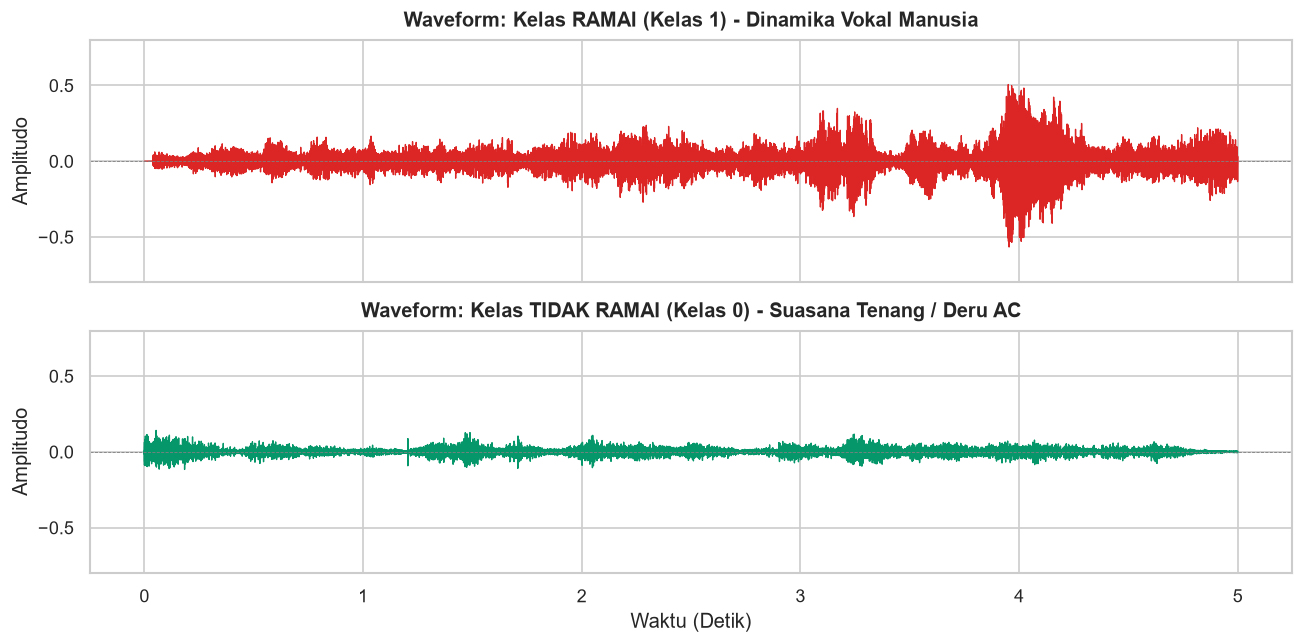

In [2]:
# Muat 1 sampel representatif kelas Ramai dan 1 sampel Tidak Ramai
sample_ramai_path = os.path.join("..", "data", "02_chunks", "ramai", "ramai_001__chunk01.wav")
sample_sepi_path = os.path.join("..", "data", "02_chunks", "tidak_ramai", "tidak_ramai_001__chunk01.wav")

y_ramai, sr_ramai = librosa.load(sample_ramai_path, sr=16000, mono=True)
y_sepi, sr_sepi = librosa.load(sample_sepi_path, sr=16000, mono=True)

time_ramai = np.linspace(0, len(y_ramai) / sr_ramai, num=len(y_ramai))
time_sepi = np.linspace(0, len(y_sepi) / sr_sepi, num=len(y_sepi))

fig, axs = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)

axs[0].plot(time_ramai, y_ramai, color="#dc2626", lw=0.8)
axs[0].set_title("Waveform: Kelas RAMAI (Kelas 1) - Dinamika Vokal Manusia", fontweight="bold", pad=8)
axs[0].set_ylabel("Amplitudo")
axs[0].set_ylim(-0.8, 0.8)
axs[0].axhline(0, color="gray", ls="--", lw=0.5)

axs[1].plot(time_sepi, y_sepi, color="#059669", lw=0.8)
axs[1].set_title("Waveform: Kelas TIDAK RAMAI (Kelas 0) - Suasana Tenang / Deru AC", fontweight="bold", pad=8)
axs[1].set_xlabel("Waktu (Detik)")
axs[1].set_ylabel("Amplitudo")
axs[1].set_ylim(-0.8, 0.8)
axs[1].axhline(0, color="gray", ls="--", lw=0.5)

plt.tight_layout()
plt.show()


---
## 2. Analisis Sinyal Domain Frekuensi (*Mel-Spectrogram*)
*Mel-Spectrogram* mengonversi spektrum daya frekuensi Hertz ke skala Mel non-linear yang meniru sensitivitas telinga manusia terhadap nada:
- **Kelas Ramai:** Memperlihatkan pita energi padat yang dinamis pada frekuensi $300 - 3.400\text{ Hz}$ (daerah forman vokal manusia F1, F2, F3).
- **Kelas Tidak Ramai:** Energi terkonsentrasi di frekuensi rendah di bawah $250\text{ Hz}$ (deru kompresor AC), sementara daerah frekuensi vokal tampak gelap (daya $< -60\text{ dB}$).


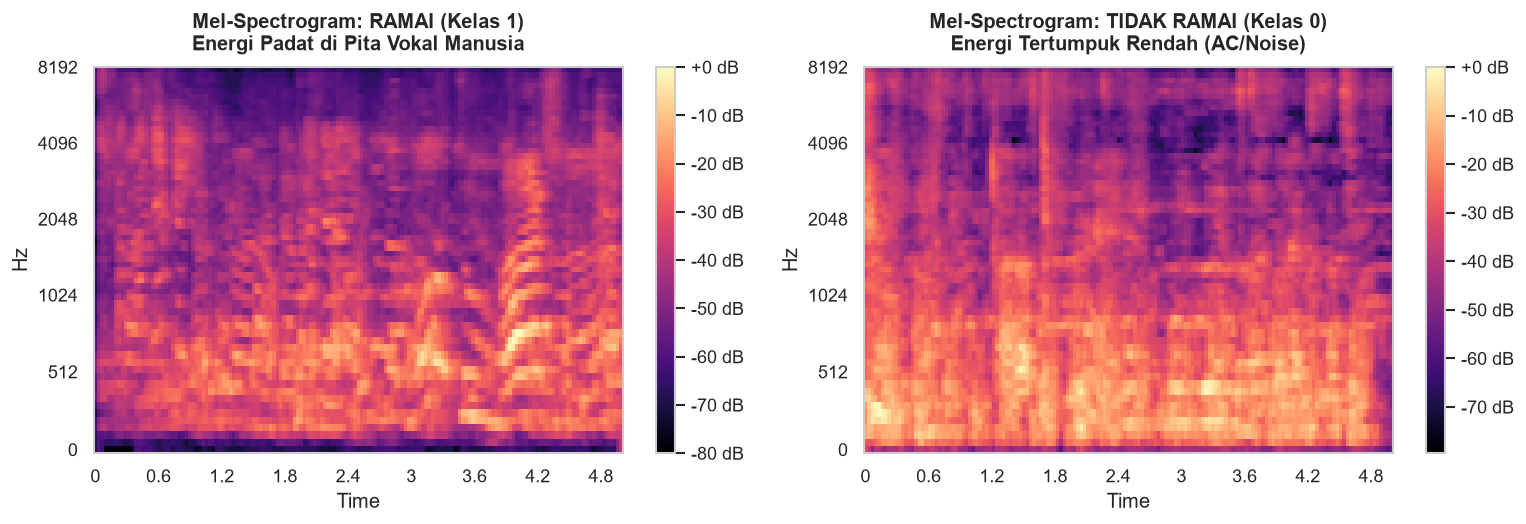

In [3]:
S_ramai = librosa.feature.melspectrogram(y=y_ramai, sr=sr_ramai, n_mels=64)
S_ramai_db = librosa.power_to_db(S_ramai, ref=np.max)

S_sepi = librosa.feature.melspectrogram(y=y_sepi, sr=sr_sepi, n_mels=64)
S_sepi_db = librosa.power_to_db(S_sepi, ref=np.max)

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))

img1 = librosa.display.specshow(S_ramai_db, x_axis="time", y_axis="mel", sr=sr_ramai, ax=axs[0], cmap="magma")
fig.colorbar(img1, ax=axs[0], format="%+2.0f dB")
axs[0].set_title("Mel-Spectrogram: RAMAI (Kelas 1)\nEnergi Padat di Pita Vokal Manusia", fontweight="bold", pad=10)

img2 = librosa.display.specshow(S_sepi_db, x_axis="time", y_axis="mel", sr=sr_sepi, ax=axs[1], cmap="magma")
fig.colorbar(img2, ax=axs[1], format="%+2.0f dB")
axs[1].set_title("Mel-Spectrogram: TIDAK RAMAI (Kelas 0)\nEnergi Tertumpuk Rendah (AC/Noise)", fontweight="bold", pad=10)

plt.tight_layout()
plt.show()


In [4]:
# Pengecekan statistik awal
rms_r = librosa.feature.rms(y=y_ramai)[0]
rms_s = librosa.feature.rms(y=y_sepi)[0]
cent_r = librosa.feature.spectral_centroid(y=y_ramai, sr=sr_ramai)[0]
cent_s = librosa.feature.spectral_centroid(y=y_sepi, sr=sr_sepi)[0]

print("=== PERBANDINGAN NILAI FISIS SAMPEL AUDIO 5 DETIK ===")
print(f"RMS Mean          : Ramai = {np.mean(rms_r):.5f} | Tidak Ramai = {np.mean(rms_s):.5f}  (Rasio: {np.mean(rms_r)/np.mean(rms_s):.2f}x)")
print(f"RMS Std (Variasi) : Ramai = {np.std(rms_r):.5f} | Tidak Ramai = {np.std(rms_s):.5f}  (Rasio: {np.std(rms_r)/np.std(rms_s):.2f}x)")
print(f"Spectral Centroid : Ramai = {np.mean(cent_r):.1f} Hz | Tidak Ramai = {np.mean(cent_s):.1f} Hz (+{np.mean(cent_r)-np.mean(cent_s):.1f} Hz)")


=== PERBANDINGAN NILAI FISIS SAMPEL AUDIO 5 DETIK ===
RMS Mean          : Ramai = 0.05966 | Tidak Ramai = 0.01987  (Rasio: 3.00x)
RMS Std (Variasi) : Ramai = 0.03698 | Tidak Ramai = 0.00837  (Rasio: 4.42x)
Spectral Centroid : Ramai = 1856.3 Hz | Tidak Ramai = 1619.5 Hz (+236.8 Hz)


> **🧭 Navigasi Proyek CRISP-DM:**
> [🏠 00. Business Understanding](./00_Index_dan_Business_Understanding.ipynb) | [📊 01. Data Understanding & EDA](./01_Data_Understanding_dan_EDA.ipynb) | [⚙️ 02. Data Preparation & 32 Fitur](./02_Data_Preparation_Chunking_dan_Ekstraksi_32Fitur.ipynb) | [🧠 03. Modeling & Benchmarking](./03_Modeling_dan_Benchmarking.ipynb) | [🚀 04. Evaluation & Deployment](./04_Evaluation_dan_Simulasi_Deployment.ipynb)